# Customer Churn Prediction & Business Insights
**Goal:** predict which telecom customers will leave (churn), find out *why*, and suggest how to keep them.

Dataset: IBM Telco Customer Churn, 7,043 customers, 21 columns.

Run each cell in order with **Shift + Enter**.

## Step 1: Load the data

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 2: Understand the data
`info()` shows each column's type. Notice **TotalCharges is stored as text** (`object` or `str`), not a number. That is a data problem we fix in Step 3.

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [18]:
# The target: how many customers churned?
print(df["Churn"].value_counts())
print()
print("Churn rate:", round((df["Churn"] == "Yes").mean() * 100, 1), "%")

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn rate: 26.5 %


Only about **27% churned**. The data is **imbalanced**: a lazy model that always says "No churn" would already be 73% *accurate* while catching zero churners. That is why we will judge models with **precision, recall and F1**, not accuracy.

## Step 3: Clean the data (missing values)

In [19]:
# TotalCharges has blank strings " " for brand-new customers -> convert to numbers
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")   # blanks become NaN
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())

# These customers have tenure 0 (just joined), so they have paid nothing yet -> fill with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# customerID is just a label, it cannot predict anything
df = df.drop(columns=["customerID"])

# Turn the target into numbers: Yes -> 1, No -> 0
df["Churn"] = (df["Churn"] == "Yes").astype(int)
print("Missing values left:", df.isna().sum().sum())

Missing TotalCharges: 11
Missing values left: 0


## Step 4: Exploratory Data Analysis (EDA)
EDA = looking at the data with charts and summaries *before* building a model, to find patterns.

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64


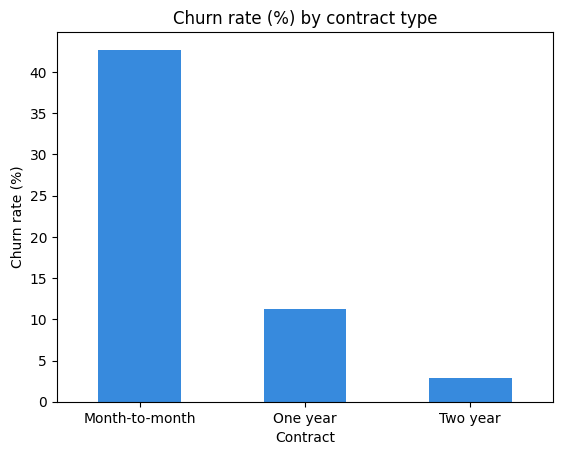

In [20]:
# Churn rate by contract type
contract = df.groupby("Contract")["Churn"].mean().sort_values(ascending=False) * 100
print(contract.round(1))

contract.plot(kind="bar", color="#378ADD", title="Churn rate (%) by contract type")
plt.ylabel("Churn rate (%)"); plt.xticks(rotation=0); plt.show()

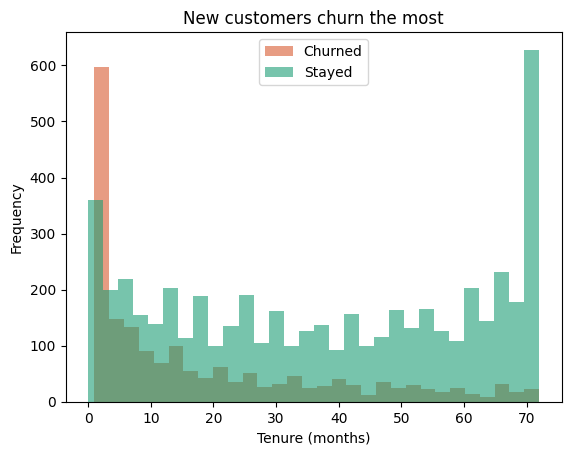

In [21]:
# Tenure (months with the company): churners vs non-churners
df[df["Churn"] == 1]["tenure"].plot(kind="hist", bins=30, alpha=0.6, label="Churned", color="#D85A30")
df[df["Churn"] == 0]["tenure"].plot(kind="hist", bins=30, alpha=0.6, label="Stayed", color="#1D9E75")
plt.xlabel("Tenure (months)"); plt.title("New customers churn the most"); plt.legend(); plt.show()

In [22]:
# Monthly charges: churners pay more on average
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

Churn
0    61.27
1    74.44
Name: MonthlyCharges, dtype: float64


## Step 5: SQL-based analysis
We load the table into an in-memory **SQLite** database and answer business questions with SQL.

In [23]:
import sqlite3
con = sqlite3.connect(":memory:")
df.to_sql("customers", con, index=False)

def sql(q):
    return pd.read_sql(q, con)

# Churn rate by contract type
sql('''
SELECT Contract,
       COUNT(*)                         AS customers,
       ROUND(AVG(Churn) * 100, 1)       AS churn_rate_pct
FROM customers
GROUP BY Contract
ORDER BY churn_rate_pct DESC
''')

,Contract,customers,churn_rate_pct
0,Month-to-month,3875,42.7
1,One year,1473,11.3
2,Two year,1695,2.8


In [24]:
# Churn rate by tenure band
sql('''
SELECT CASE
         WHEN tenure <= 12 THEN '0-12 months'
         WHEN tenure <= 24 THEN '13-24 months'
         WHEN tenure <= 48 THEN '25-48 months'
         ELSE '49+ months'
       END                              AS tenure_band,
       COUNT(*)                         AS customers,
       ROUND(AVG(Churn) * 100, 1)       AS churn_rate_pct
FROM customers
GROUP BY tenure_band
ORDER BY churn_rate_pct DESC
''')

,tenure_band,customers,churn_rate_pct
0,0-12 months,2186,47.4
1,13-24 months,1024,28.7
2,25-48 months,1594,20.4
3,49+ months,2239,9.5


In [25]:
# Churn rate by payment method
sql('''
SELECT PaymentMethod,
       ROUND(AVG(Churn) * 100, 1) AS churn_rate_pct
FROM customers
GROUP BY PaymentMethod
ORDER BY churn_rate_pct DESC
''')

,PaymentMethod,churn_rate_pct
0,Electronic check,45.3
1,Mailed check,19.1
2,Bank transfer (automatic),16.7
3,Credit card (automatic),15.2


## Step 6: Prepare data for the model
- **Features (X)** = the input columns. **Label / target (y)** = `Churn`.
- Models only understand numbers, so text columns are **one-hot encoded**: `Contract` becomes `Contract_One year` and `Contract_Two year`, each 0 or 1.
- We split into **80% training data** (model learns) and **20% test data** (model is checked on customers it has never seen).

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = pd.get_dummies(df.drop(columns=["Churn"]), drop_first=True)   # one-hot encoding
y = df["Churn"]
print("Number of features after encoding:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)   # stratify keeps the 27% churn ratio in both parts

# Scaling: put numbers on the same scale (needed for Logistic Regression)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit ONLY on training data
X_test_s = scaler.transform(X_test)
print("Train:", X_train.shape, " Test:", X_test.shape)

Number of features after encoding: 30
Train: (5634, 30)  Test: (1409, 30)


## Step 7: Train three models
`class_weight="balanced"` tells each model that missing a churner is costly, which handles the class imbalance.

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree":       DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=200, max_depth=8, class_weight="balanced", random_state=42),
}

results = []
for name, model in models.items():
    Xtr, Xte = (X_train_s, X_test_s) if name == "Logistic Regression" else (X_train, X_test)
    model.fit(Xtr, y_train)          # learn from training data
    pred = model.predict(Xte)        # predict on unseen test data
    results.append({
        "Model": name,
        "Accuracy":  round(accuracy_score(y_test, pred), 3),
        "Precision": round(precision_score(y_test, pred), 3),
        "Recall":    round(recall_score(y_test, pred), 3),
        "F1":        round(f1_score(y_test, pred), 3),
    })

pd.DataFrame(results)

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.740,0.507,0.786,0.616
1,Decision Tree,0.735,0.500,0.807,0.618
2,Random Forest,0.764,0.538,0.783,0.638


## Step 8: Confusion matrix of the best model (Random Forest, highest F1)
A confusion matrix counts the 4 possible outcomes: correct churn (TP), false alarm (FP), missed churner (FN), correct stay (TN).

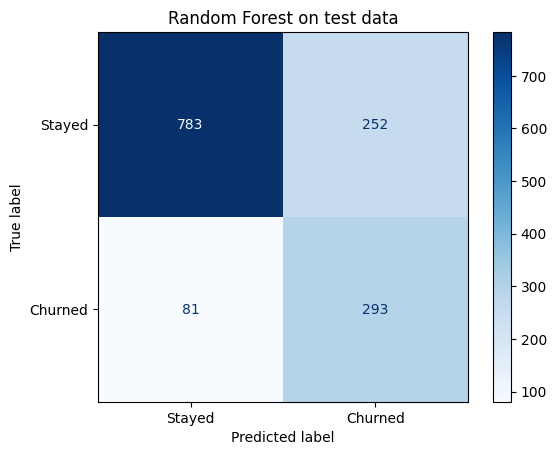

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best = models["Random Forest"]
pred = best.predict(X_test)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stayed", "Churned"]).plot(cmap="Blues")
plt.title("Random Forest on test data"); plt.show()

## Step 9: Which features drive churn?
Random Forest tells us how much each feature helped its decisions (**feature importance**).

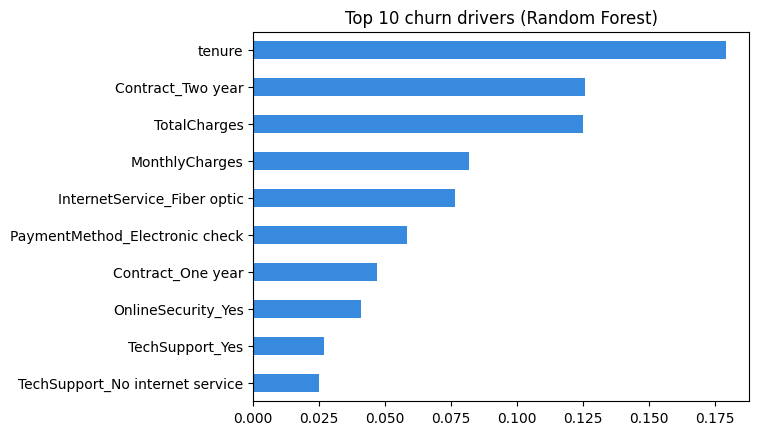

In [29]:
rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
importance.sort_values().plot(kind="barh", color="#378ADD", title="Top 10 churn drivers (Random Forest)")
plt.show()

In [30]:
import joblib

# Save the trained model to a file
joblib.dump(rf, "churn_model.pkl")

# Later (or in another program): load it and predict for a new customer
model = joblib.load("churn_model.pkl")
customer = X_test.iloc[[0]]                     # one customer's 30 features
print("Will churn?", model.predict(customer)[0])                       # 0 or 1
print("Churn probability:", round(model.predict_proba(customer)[0][1], 2))

Will churn? 0
Churn probability: 0.06


## Step 10: Business recommendations
1. **Move month-to-month customers to longer contracts.** They churn far more than one- or two-year customers; offer a discount for switching to a yearly plan.
2. **Look after new customers.** Churn is highest in the first 12 months; give them an onboarding call and a first-year loyalty offer.
3. **Push automatic payments.** Electronic-check users churn the most; reward switching to auto-pay.
4. **Use the model weekly.** Score every customer, and send the high-risk list to the retention team before they leave.